# Dataset C: Covid Vaccine Analysis and Modeling
We will start by importing the necessary libraries and loading the dataset.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

train = pd.read_csv("dataset_C_training.csv")
test = pd.read_csv("dataset_C_testing.csv")

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

display(train.head())


Saving dataset_C_testing.csv to dataset_C_testing (5).csv
Saving dataset_C_training.csv to dataset_C_training (4).csv
Training shape: (4756, 31)
Testing shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


In [ ]:

print("Dataset information:")
train.info()

print("\nSummary statistics:")
display(train.describe(include="all").T)

print("\nDuplicate respondent IDs:")
print(train["respondent_id"].duplicated().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   covid_concern                  4744 non-null   float64
 2   covid_knowledge                4729 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4729 non-null   float64
 5   behavioral_face_mask           4754 non-null   float64
 6   behavioral_wash_hands          4747 non-null   float64
 7   behavioral_large_gatherings    4746 non-null   float64
 8   behavioral_outside_home        4742 non-null   float64
 9   behavioral_touch_face          4735 non-null   float64
 10  child_under_6_months           4621 non-null   float64
 11  health_worker                  4624 non-null   float64
 12  health_insurance           

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
covid_concern,4744.0,NaN,NaN,NaN,1.648609,0.903204,0.0,1.0,2.0,2.0,3.0
covid_knowledge,4729.0,NaN,NaN,NaN,1.296469,0.615705,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.053353,0.22476,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4729.0,NaN,NaN,NaN,0.733347,0.442256,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4754.0,NaN,NaN,NaN,0.072991,0.260149,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4747.0,NaN,NaN,NaN,0.839267,0.367323,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4746.0,NaN,NaN,NaN,0.3563,0.478956,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4742.0,NaN,NaN,NaN,0.329186,0.469967,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4735.0,NaN,NaN,NaN,0.693981,0.460886,0.0,0.0,1.0,1.0,1.0



Duplicate respondent IDs:
0


,Missing Count,Missing Percentage
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


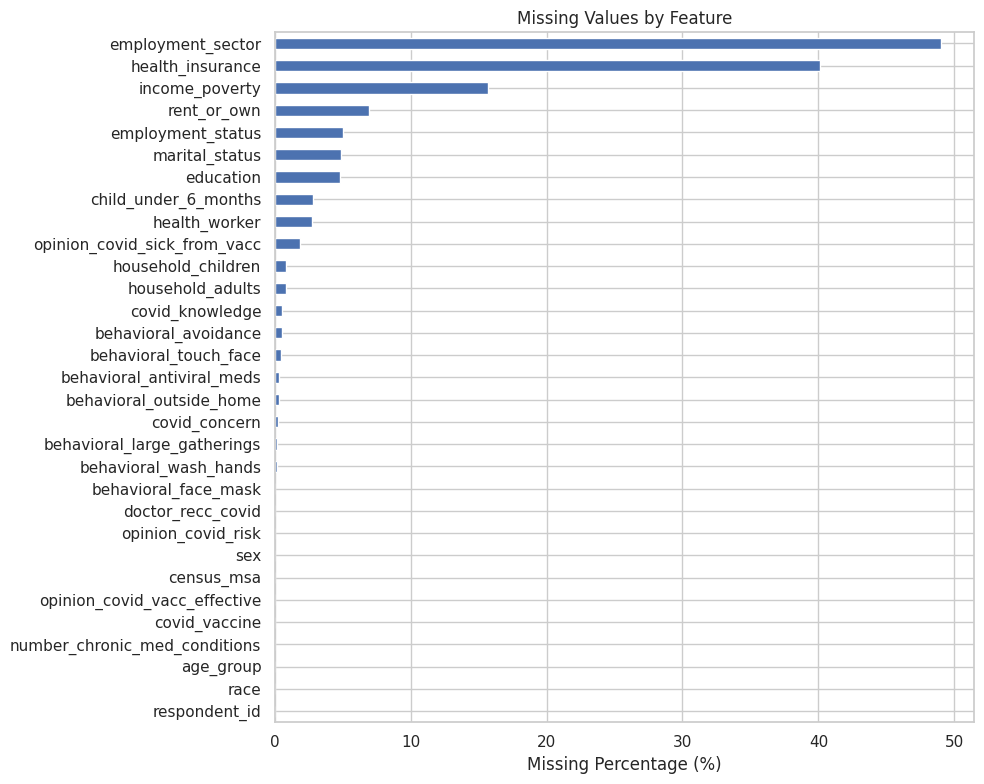

In [ ]:

missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean() * 100
})

display(missing.sort_values(
    "Missing Percentage", ascending=False
))

plt.figure(figsize=(10, 8))
missing["Missing Percentage"].sort_values().plot(
    kind="barh"
)
plt.title("Missing Values by Feature")
plt.xlabel("Missing Percentage (%)")
plt.tight_layout()
plt.show()


covid_vaccine
0    3202
1    1554
Name: count, dtype: int64
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


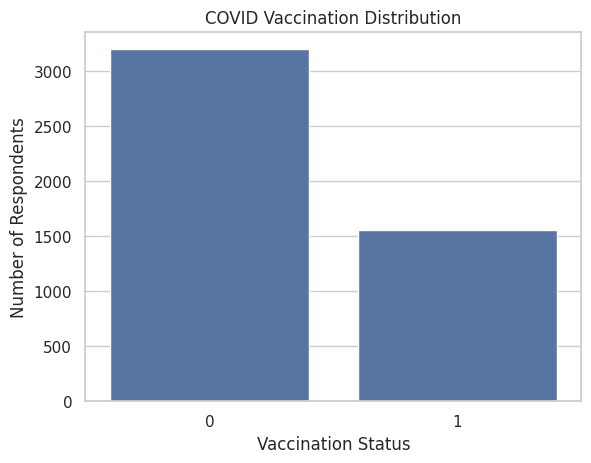

In [ ]:

print(train["covid_vaccine"].value_counts())
print(train["covid_vaccine"].value_counts(normalize=True) * 100)

sns.countplot(data=train, x="covid_vaccine")
plt.title("COVID Vaccination Distribution")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.show()


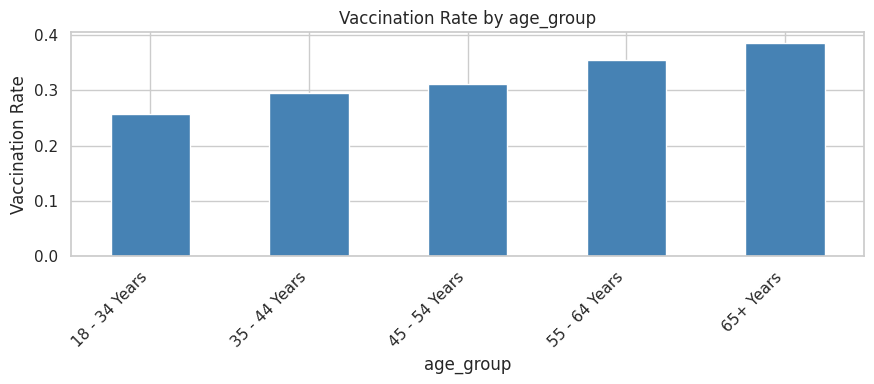

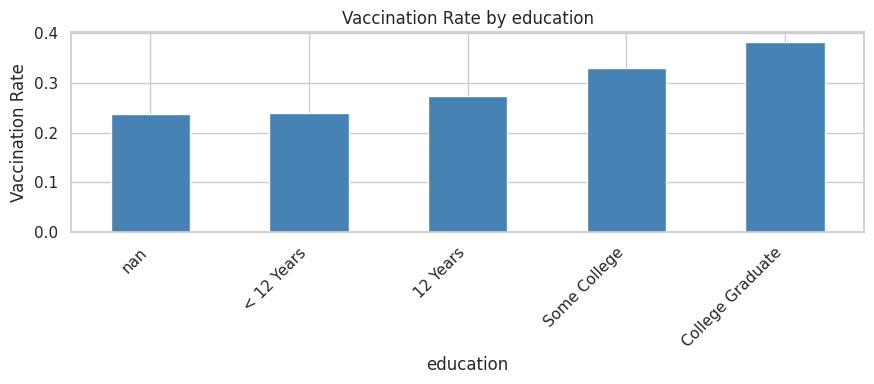

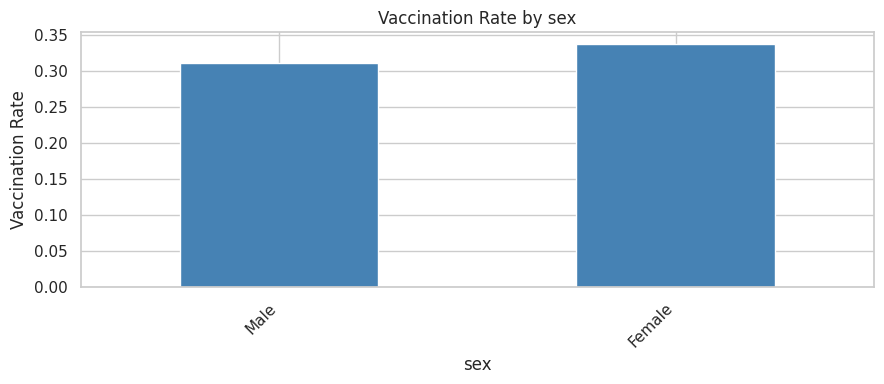

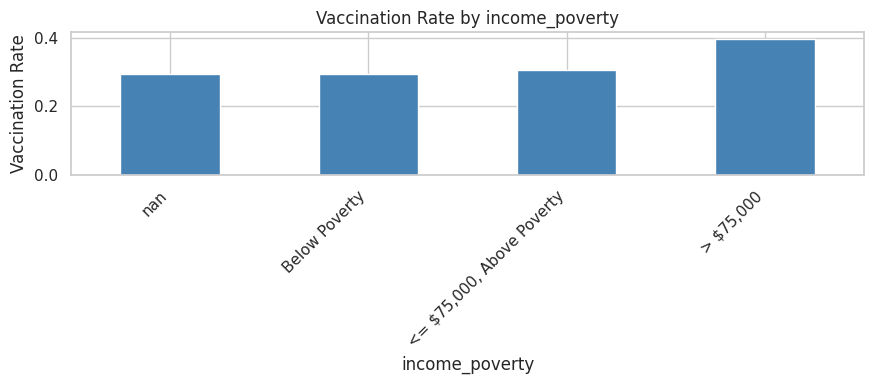

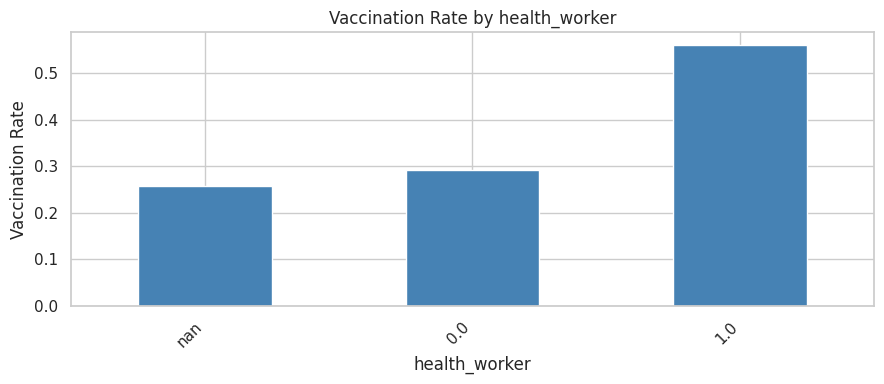

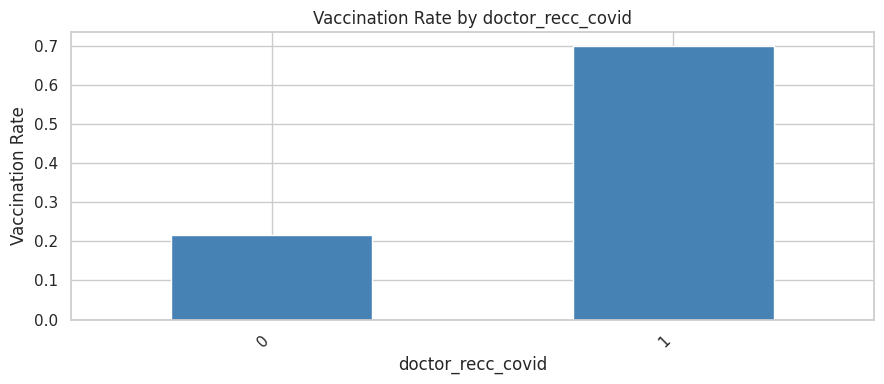

In [ ]:

features = [
    "age_group",
    "education",
    "sex",
    "income_poverty",
    "health_worker",
    "doctor_recc_covid"
]

for feature in features:
    plt.figure(figsize=(9, 4))

    rates = train.groupby(feature, dropna=False)[
        "covid_vaccine"
    ].mean().sort_values()

    rates.plot(kind="bar", color="steelblue")
    plt.title(f"Vaccination Rate by {feature}")
    plt.ylabel("Vaccination Rate")
    plt.xlabel(feature)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


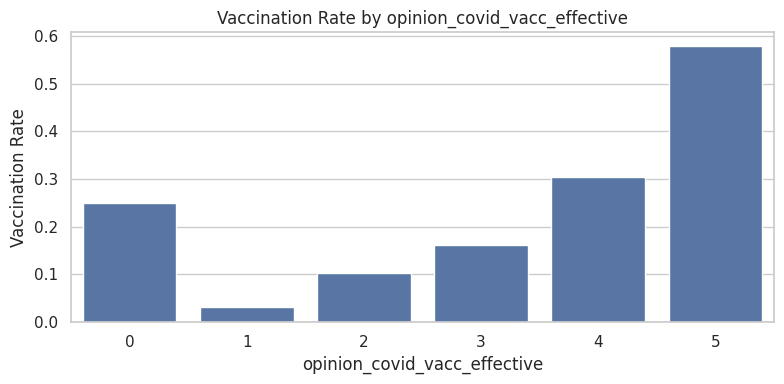

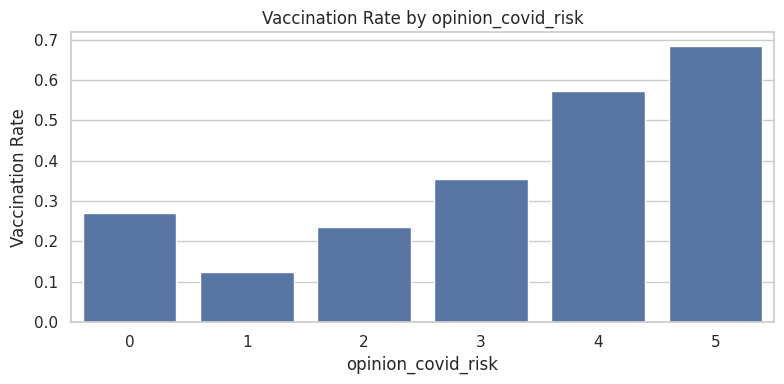

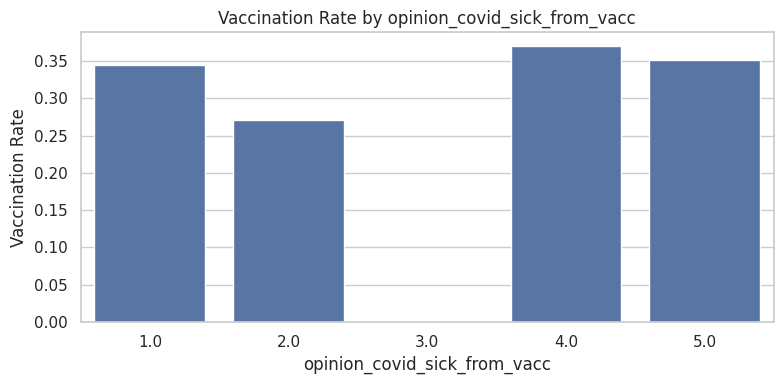

In [ ]:

opinion_features = [
    "opinion_covid_vacc_effective",
    "opinion_covid_risk",
    "opinion_covid_sick_from_vacc"
]

for feature in opinion_features:
    plt.figure(figsize=(8, 4))
    sns.barplot(
        data=train,
        x=feature,
        y="covid_vaccine",
        errorbar=None
    )
    plt.title(f"Vaccination Rate by {feature}")
    plt.ylabel("Vaccination Rate")
    plt.tight_layout()
    plt.show()


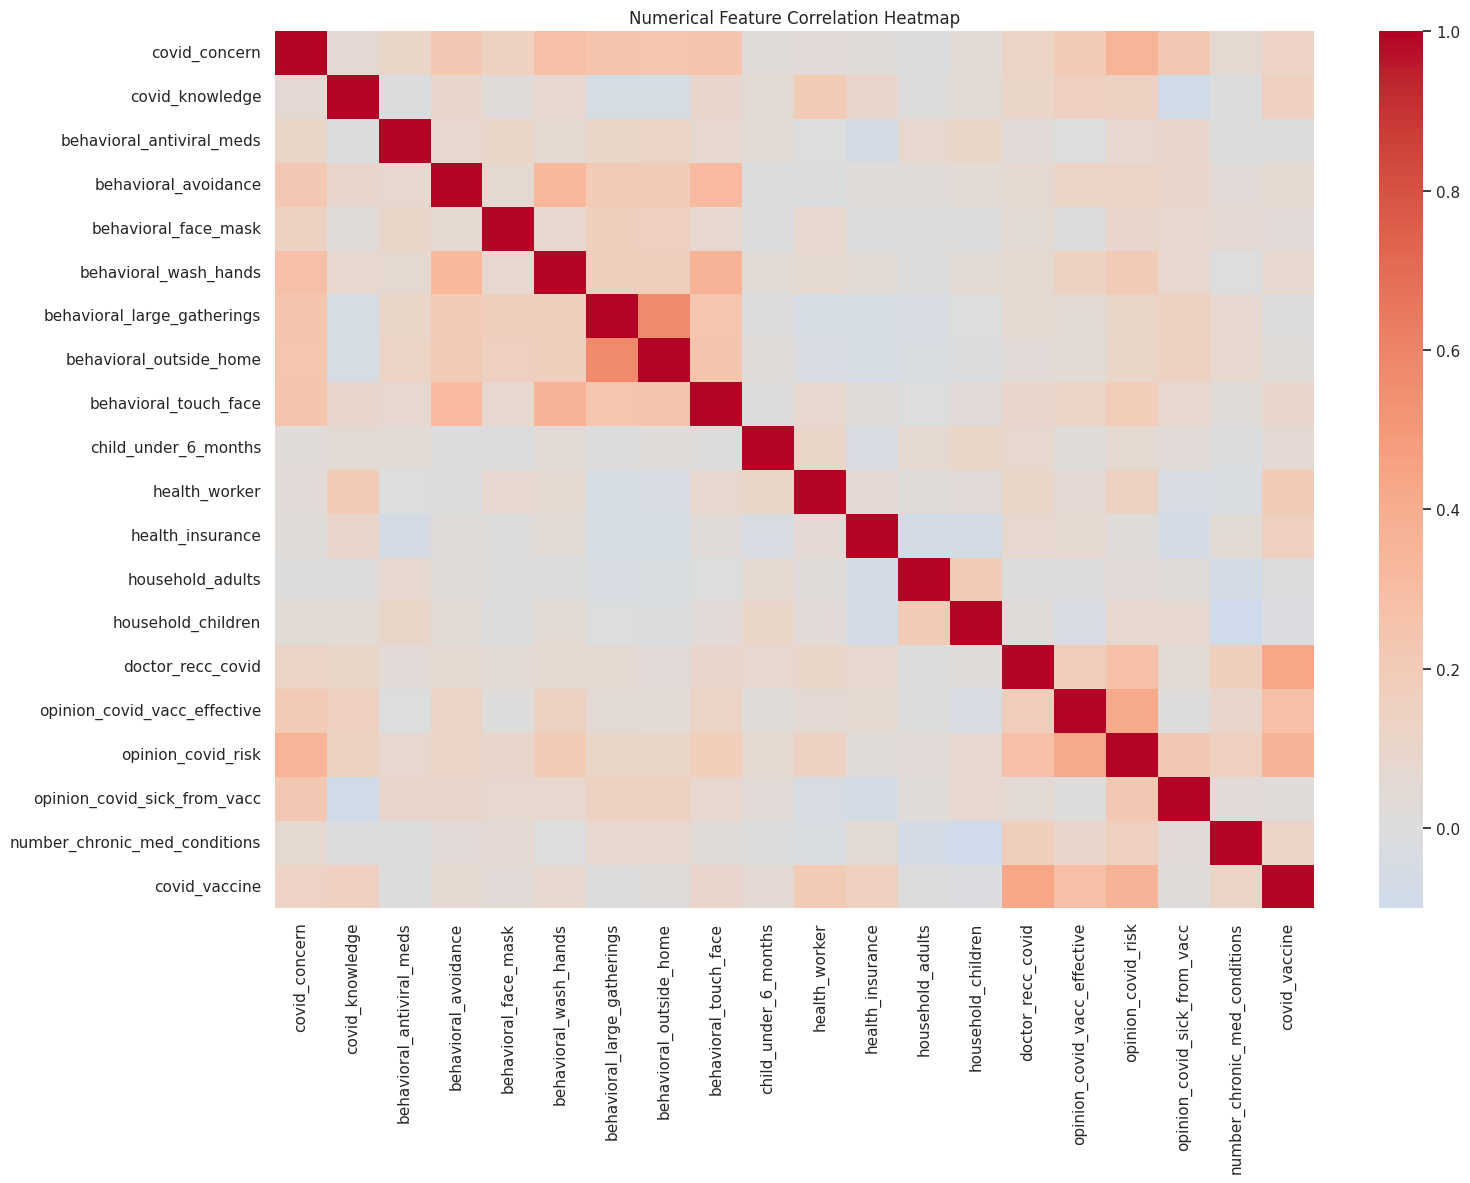

In [ ]:

numeric_data = train.select_dtypes(include=np.number)
numeric_data = numeric_data.drop(
    columns=["respondent_id"], errors="ignore"
)

plt.figure(figsize=(16, 12))
sns.heatmap(
    numeric_data.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X = train.drop(
    columns=["respondent_id", "covid_vaccine"]
)
y = train["covid_vaccine"]

X_test = test.drop(columns=["respondent_id"])

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)


Training: (3804, 29)
Validation: (952, 29)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    )
}

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_val)
    y_prob = pipeline.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)
display(results_df.sort_values("ROC-AUC", ascending=False))


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Gradient Boosting,0.800420,0.744939,0.591640,0.659498,0.830801
0,Logistic Regression,0.799370,0.750000,0.578778,0.653358,0.827034
1,Random Forest,0.769958,0.711009,0.498392,0.586011,0.815767
3,Extra Trees,0.777311,0.721973,0.517685,0.602996,0.811734


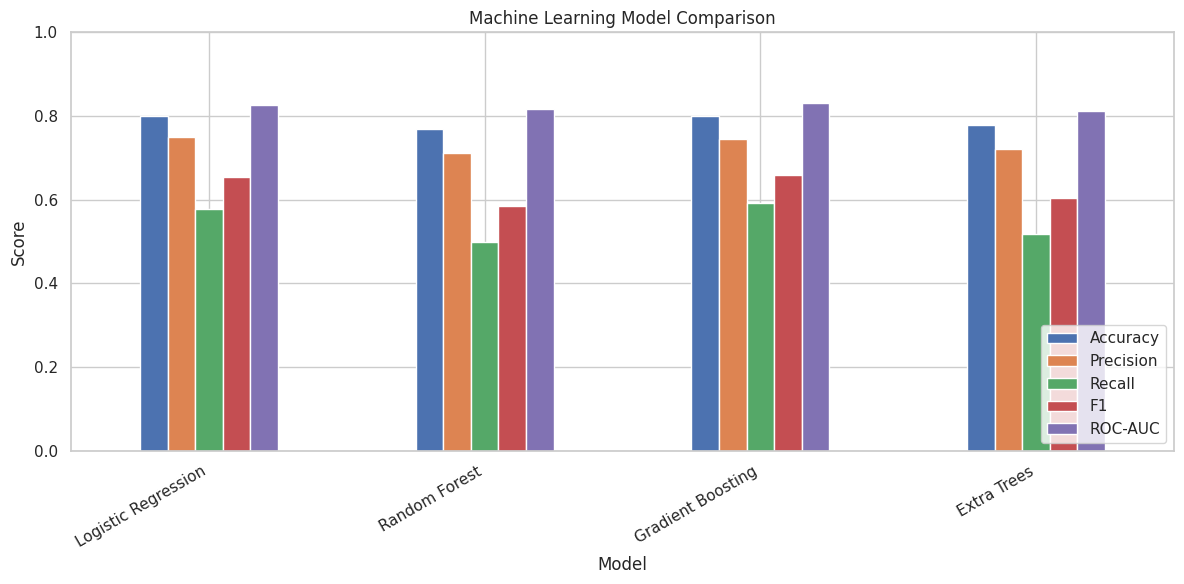

In [ ]:

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Best ROC-AUC model: Gradient Boosting
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       641
           1       0.74      0.59      0.66       311

    accuracy                           0.80       952
   macro avg       0.78      0.75      0.76       952
weighted avg       0.80      0.80      0.79       952



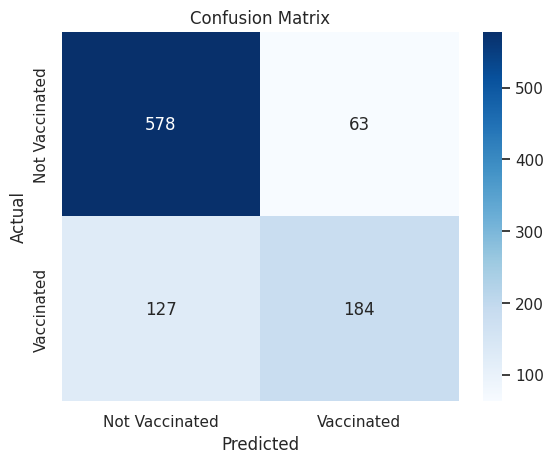

In [ ]:

best_name = results_df.sort_values(
    "ROC-AUC", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]
y_pred = best_model.predict(X_val)

print("Best ROC-AUC model:", best_name)
print(classification_report(y_val, y_pred))

sns.heatmap(
    confusion_matrix(y_val, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Vaccinated", "Vaccinated"],
    yticklabels=["Not Vaccinated", "Vaccinated"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [ ]:

from sklearn.metrics import confusion_matrix

COST_FP = 1500
COST_FN = 41000

def calculate_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return (fp * COST_FP) + (fn * COST_FN)

cost_results = []

for name, model in trained_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    cost_results.append({
        "Model": name,
        "Illustrative Cost": calculate_cost(
            y_val, predictions
        )
    })

cost_df = pd.DataFrame(cost_results)
display(cost_df.sort_values("Illustrative Cost"))


,Model,Illustrative Cost
2,Gradient Boosting,5301500
0,Logistic Regression,5461000
3,Extra Trees,6165500
1,Random Forest,6369000


In [ ]:

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline, X, y,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores["test_accuracy"].mean(),
        "Mean F1": scores["test_f1"].mean(),
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df.sort_values("Mean ROC-AUC", ascending=False))


,Model,Mean Accuracy,Mean F1,Mean ROC-AUC,ROC-AUC Std
2,Gradient Boosting,0.800464,0.658648,0.838961,0.005808
0,Logistic Regression,0.794156,0.642651,0.830669,0.008067
1,Random Forest,0.782170,0.615338,0.824498,0.009771
3,Extra Trees,0.780488,0.609679,0.813000,0.007406


In [ ]:

from sklearn.model_selection import RandomizedSearchCV

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 150, 200, 300],
    "classifier__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_samples_leaf": [1, 5, 10]
}

search = RandomizedSearchCV(
    gb_pipeline,
    param_distributions=param_grid,
    n_iter=12,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("Best cross-validation ROC-AUC:")
print(search.best_score_)

tuned_model = search.best_estimator_

tuned_prob = tuned_model.predict_proba(X_val)[:, 1]
print("Validation ROC-AUC:",
      roc_auc_score(y_val, tuned_prob))


Best parameters:
{'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.1}
Best cross-validation ROC-AUC:
0.8382379314708474
Validation ROC-AUC: 0.8350748177837082


,Feature,Importance
14,num__doctor_recc_covid,0.450880
16,num__opinion_covid_risk,0.185933
15,num__opinion_covid_vacc_effective,0.123804
10,num__health_worker,0.038055
1,num__covid_knowledge,0.030840
64,cat__employment_sector_technology,0.023950
23,cat__age_group_65+ Years,0.016061
55,cat__employment_sector_healthcare,0.012920
25,cat__education_< 12 Years,0.011961
31,cat__race_White,0.011137


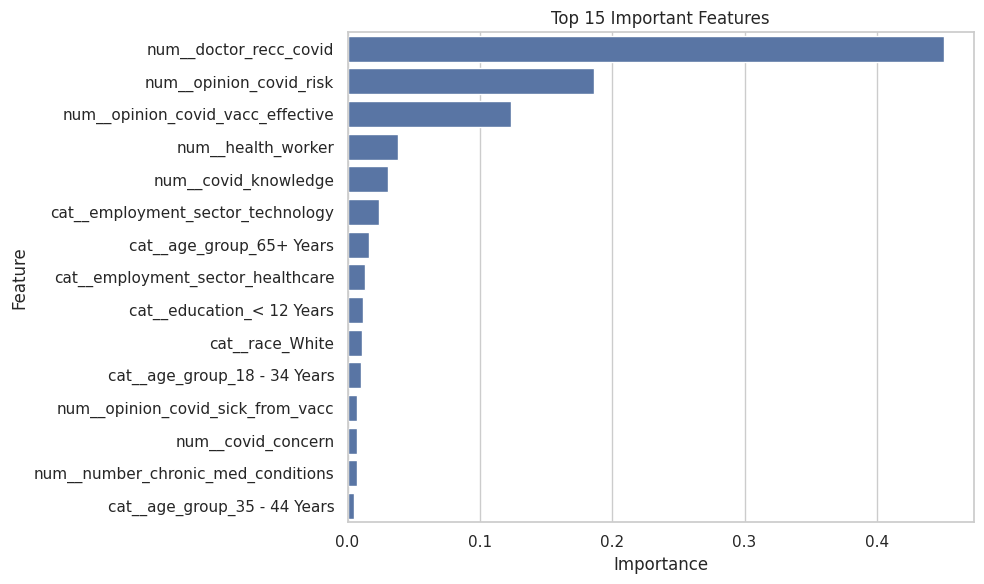

In [ ]:

feature_names = tuned_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = tuned_model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.base import clone

candidate_models = dict(trained_models)
candidate_models["Tuned Gradient Boosting"] = tuned_model

ranked = []

for name, model in candidate_models.items():
    probabilities = model.predict_proba(X_val)[:, 1]
    score = roc_auc_score(y_val, probabilities)
    ranked.append((name, score))

ranked.sort(key=lambda x: x[1], reverse=True)

for rank, (name, score) in enumerate(ranked[:5], start=1):
    final_model = clone(candidate_models[name])
    final_model.fit(X, y)

    predictions = final_model.predict(X_test)

    submission = pd.DataFrame({
        "respondent_id": test["respondent_id"],
        "covid_vaccine": predictions.astype(int)
    })

    filename = f"dataset_C_submission_{rank}.csv"
    submission.to_csv(filename, index=False)

    print(rank, name, "ROC-AUC:", round(score, 4))
    print("Saved:", filename)


1 Tuned Gradient Boosting ROC-AUC: 0.8351
Saved: dataset_C_submission_1.csv
2 Gradient Boosting ROC-AUC: 0.8308
Saved: dataset_C_submission_2.csv
3 Logistic Regression ROC-AUC: 0.827
Saved: dataset_C_submission_3.csv
4 Random Forest ROC-AUC: 0.8158
Saved: dataset_C_submission_4.csv
5 Extra Trees ROC-AUC: 0.8117
Saved: dataset_C_submission_5.csv


In [ ]:

from google.colab import files

results_df.to_csv("model_comparison.csv", index=False)
cv_df.to_csv("cross_validation.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)

files.download("model_comparison.csv")
files.download("cross_validation.csv")
files.download("feature_importance.csv")

for i in range(1, 6):
    files.download(f"dataset_C_submission_{i}.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>